# 🚗 RoadVision DUET — YOLOv11x Full Training Pipeline
**Strategy:** VisDrone Pretraining → Bangladesh Fine-tuning → TTA + SAHI Inference → Submission

**Expected mAP@0.5:** 0.65–0.75+

Public - 0.57428

## 📦 Cell 1 — Install Dependencies

In [1]:
!pip install -q ultralytics sahi ensemble-boxes
!pip install -q albumentations --upgrade

import os, shutil, random, json, glob, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
from ultralytics import YOLO

warnings.filterwarnings('ignore')

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 9.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.


## ⚙️ Cell 2 — Config (All Paths & Hyperparameters in One Place)

In [2]:
# ============================================================
#  PATHS
# ============================================================
TRAIN_IMAGES_DIR = Path('/kaggle/input/competitions/road-vision/RoadVision_DUET/train/images')
TRAIN_CSV        = Path('/kaggle/input/competitions/road-vision/RoadVision_DUET/train/train.csv')
TEST_IMAGES_DIR  = Path('/kaggle/input/competitions/road-vision/RoadVision_DUET/test/images')
WORK_DIR         = Path('/kaggle/working')
DATASET_DIR      = WORK_DIR / 'dataset'
MODELS_DIR       = WORK_DIR / 'models'
SUBMISSION_DIR   = WORK_DIR / 'submission'

for d in [DATASET_DIR, MODELS_DIR, SUBMISSION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ============================================================
#  CLASSES
# ============================================================
CLASS_NAMES = [
    'Rickshaw',    # 0
    'Motorcycle',  # 1
    'Tempu',       # 2
    'Sedan Car',   # 3
    'Pickup',      # 4
    'Microbus',    # 5
    'Mini Bus',    # 6
    'Mini Truck',  # 7
    'Agro Use',    # 8
    'Medium Truck',# 9
    'Large Bus',   # 10
    'Heavy Truck', # 11
    'Trailer',     # 12
]
NUM_CLASSES = len(CLASS_NAMES)

# ============================================================
#  HYPERPARAMETERS
# ============================================================
VISDRONE_EPOCHS  = 50       # Intermediate pretraining
FINETUNE_EPOCHS  = 250      # Fine-tuning on Bangladesh data
IMG_SIZE         = 1280     # High-res for small objects in CCTV
VAL_SPLIT        = 0.15     # 15% validation
RANDOM_SEED      = 42
CONF_THRESH      = 0.001    # Very low — NMS will clean up
IOU_THRESH       = 0.5

# SAHI slicing config
SAHI_SLICE_H     = 640
SAHI_SLICE_W     = 640
SAHI_OVERLAP     = 0.2

print('✅ Config loaded.')
print(f'   Classes  : {NUM_CLASSES}')
print(f'   Image sz : {IMG_SIZE}')
print(f'   VisDrone : {VISDRONE_EPOCHS} epochs')
print(f'   Finetune : {FINETUNE_EPOCHS} epochs')

✅ Config loaded.
   Classes  : 13
   Image sz : 1280
   VisDrone : 50 epochs
   Finetune : 250 epochs


## 📊 Cell 3 — EDA & Class Distribution

Total annotations : 10475
Unique images     : 810
Classes present   : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]



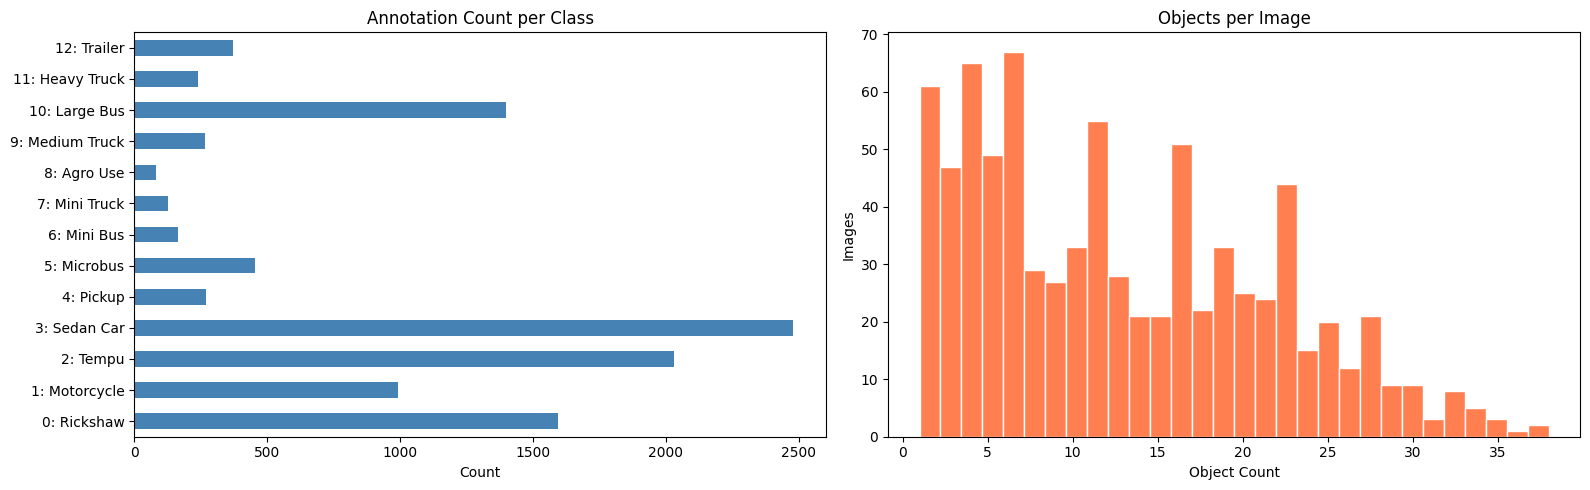


Class counts:
0: Rickshaw        1594
1: Motorcycle       993
2: Tempu           2032
3: Sedan Car       2480
4: Pickup           270
5: Microbus         455
6: Mini Bus         164
7: Mini Truck       127
8: Agro Use          83
9: Medium Truck     265
10: Large Bus      1401
11: Heavy Truck     239
12: Trailer         372


In [3]:
df = pd.read_csv(TRAIN_CSV)
print(f'Total annotations : {len(df)}')
print(f'Unique images     : {df["image_id"].nunique()}')
print(f'Classes present   : {sorted(df["class_id"].unique())}\n')

# Class distribution
class_counts = df['class_id'].value_counts().sort_index()
class_counts.index = [f'{i}: {CLASS_NAMES[i]}' for i in class_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

class_counts.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Annotation Count per Class')
axes[0].set_xlabel('Count')

# Objects per image distribution
objs_per_img = df.groupby('image_id').size()
axes[1].hist(objs_per_img, bins=30, color='coral', edgecolor='white')
axes[1].set_title('Objects per Image')
axes[1].set_xlabel('Object Count')
axes[1].set_ylabel('Images')

plt.tight_layout()
plt.savefig(WORK_DIR / 'eda_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
print('\nClass counts:')
print(class_counts.to_string())

## 🗂️ Cell 4 — Stratified Train/Val Split & YOLO Label Creation

In [4]:
# --------------------------------------------------
#  Robust stratified split — handles rare classes
#  (classes with only 1 image are kept in train)
# --------------------------------------------------
img_dominant = (
    df.groupby('image_id')['class_id']
      .agg(lambda x: x.mode()[0])
      .reset_index()
)

# Count how many images each dominant class has
class_img_counts = img_dominant['class_id'].value_counts()
print('Images per dominant class:')
for cls, cnt in class_img_counts.sort_index().items():
    flag = '⚠️ (too rare to stratify)' if cnt < 2 else ''
    print(f'  Class {cls:2d} ({CLASS_NAMES[cls]:<15}): {cnt:4d} images {flag}')

# Separate rare classes (< 2 images) — always go to train
rare_classes   = set(class_img_counts[class_img_counts < 2].index)
rare_mask      = img_dominant['class_id'].isin(rare_classes)
rare_df        = img_dominant[rare_mask]
stratify_df    = img_dominant[~rare_mask]

print(f'\nImages always in train (rare classes): {len(rare_df)}')
print(f'Images for stratified split          : {len(stratify_df)}')

# Stratify only the non-rare images
if len(stratify_df) > 0:
    strat_train_ids, strat_val_ids = train_test_split(
        stratify_df['image_id'],
        test_size=VAL_SPLIT,
        stratify=stratify_df['class_id'],
        random_state=RANDOM_SEED
    )
else:
    strat_train_ids, strat_val_ids = stratify_df['image_id'], pd.Series([], dtype=str)

# Merge: rare always in train, rest split normally
train_ids = set(strat_train_ids) | set(rare_df['image_id'])
val_ids   = set(strat_val_ids)

print(f'\nFinal split:')
print(f'  Train images : {len(train_ids)}')
print(f'  Val images   : {len(val_ids)}')

# --------------------------------------------------
#  Build YOLO directory structure
# --------------------------------------------------
for split in ['train', 'val']:
    (DATASET_DIR / split / 'images').mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / split / 'labels').mkdir(parents=True, exist_ok=True)

def write_labels(image_id, split):
    """Copy image and write YOLO label file."""
    # Strip any accidental extension from image_id (e.g. '.txt', '.jpg')
    image_id_stem = Path(image_id).stem

    # Find image file (try common extensions)
    img_path = None
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        candidate = TRAIN_IMAGES_DIR / f'{image_id_stem}{ext}'
        if candidate.exists():
            img_path = candidate
            break
    if img_path is None:
        print(f'⚠️  Image not found: {image_id_stem}')
        return

    # Copy image
    dst_img = DATASET_DIR / split / 'images' / img_path.name
    shutil.copy2(img_path, dst_img)

    # Write label — match on stem too
    rows = df[df['image_id'].apply(lambda x: Path(x).stem) == image_id_stem]
    label_path = DATASET_DIR / split / 'labels' / (img_path.stem + '.txt')
    with open(label_path, 'w') as f:
        for _, row in rows.iterrows():
            f.write(f"{int(row['class_id'])} {row['x_center']:.6f} {row['y_center']:.6f} "
                    f"{row['width']:.6f} {row['height']:.6f}\n")

# Also fix: normalize image_ids when building train/val sets
train_ids = set(Path(x).stem for x in train_ids)
val_ids   = set(Path(x).stem for x in val_ids)

print('Writing YOLO labels...')
for img_id in train_ids:
    write_labels(img_id, 'train')
for img_id in val_ids:
    write_labels(img_id, 'val')

n_train_imgs = len(list((DATASET_DIR / 'train' / 'images').iterdir()))
n_val_imgs   = len(list((DATASET_DIR / 'val'   / 'images').iterdir()))
print(f'✅ Done — {n_train_imgs} train images, {n_val_imgs} val images written.')

Images per dominant class:
  Class  0 (Rickshaw       ):  160 images 
  Class  1 (Motorcycle     ):   67 images 
  Class  2 (Tempu          ):  221 images 
  Class  3 (Sedan Car      ):  215 images 
  Class  4 (Pickup         ):    2 images 
  Class  5 (Microbus       ):   13 images 
  Class  6 (Mini Bus       ):    1 images ⚠️ (too rare to stratify)
  Class  8 (Agro Use       ):    3 images 
  Class  9 (Medium Truck   ):    3 images 
  Class 10 (Large Bus      ):   46 images 
  Class 11 (Heavy Truck    ):    6 images 
  Class 12 (Trailer        ):   73 images 

Images always in train (rare classes): 1
Images for stratified split          : 809

Final split:
  Train images : 688
  Val images   : 122
Writing YOLO labels...
✅ Done — 688 train images, 122 val images written.


## 📝 Cell 5 — Generate dataset.yaml

In [5]:
yaml_content = f"""# RoadVision DUET — Bangladesh Vehicle Detection
path: {DATASET_DIR}
train: train/images
val:   val/images

nc: {NUM_CLASSES}
names:
"""
for i, name in enumerate(CLASS_NAMES):
    yaml_content += f'  {i}: {name}\n'

YAML_PATH = WORK_DIR / 'bangladesh.yaml'
with open(YAML_PATH, 'w') as f:
    f.write(yaml_content)

print('✅ bangladesh.yaml created:')
print(yaml_content)

✅ bangladesh.yaml created:
# RoadVision DUET — Bangladesh Vehicle Detection
path: /kaggle/working/dataset
train: train/images
val:   val/images

nc: 13
names:
  0: Rickshaw
  1: Motorcycle
  2: Tempu
  3: Sedan Car
  4: Pickup
  5: Microbus
  6: Mini Bus
  7: Mini Truck
  8: Agro Use
  9: Medium Truck
  10: Large Bus
  11: Heavy Truck
  12: Trailer



## 🛰️ Cell 6 — Phase 1: VisDrone Pretraining

In [6]:
# ── CELL 6 REPLACEMENT ──────────────────────────────────────
# Skip VisDrone — not enough time on Kaggle T4 12hr limit
# Start directly from COCO pretrained YOLOv11x

print('Skipping VisDrone — loading COCO pretrained yolo11x directly')
VISDRONE_BEST = 'yolov11l.pt'   # Use COCO weights as starting point
print(f'Starting weights: {VISDRONE_BEST}')

Skipping VisDrone — loading COCO pretrained yolo11x directly
Starting weights: yolov11l.pt


## 🇧🇩 Cell 7 — Phase 2: Bangladesh Fine-Tuning

In [7]:
print('='*60)
print('PHASE 2 — Bangladesh Fine-Tuning')
print('='*60)


model = YOLO('yolov8s.pt')          # Direct COCO weights, no VisDrone
                          # Reduce from 250 — fits in ~8hrs on T4

finetune_results = model.train(
    data=str(YAML_PATH),
    epochs=100,
    imgsz=1280,
    batch=16,                   # Auto-batch
    patience=50,                # Stop if no improvement for 50 epochs
    optimizer='AdamW',

    # Learning rate — lower for fine-tuning
    lr0=0.0005,                 # Half of pretraining LR
    lrf=0.005,
    warmup_epochs=5,
    cos_lr=True,
    weight_decay=0.0005,
    momentum=0.937,

    # Regularization
    dropout=0.1,
    label_smoothing=0.1,        # Helps with fine-grained classes

    # Precision & speed
    amp=True,
    cache='ram',
    workers=2,

    # Loss weights — boost box/cls for fine-grained detection
    box=7.5,
    cls=0.5,
    dfl=1.5,

    # ── AUGMENTATION ──────────────────────────────────────────
    # Color & brightness — simulate day/night/monsoon/fog
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    # Geometric
    degrees=10.0,               # Slight rotation for camera tilt
    translate=0.15,
    scale=0.6,                  # Scale jitter: handles near/far vehicles
    shear=2.0,
    perspective=0.0005,
    fliplr=0.5,
    flipud=0.1,

    # Dense scene augmentations
    mosaic=1.0,                 # Combines 4 images — critical for dense traffic
    mixup=0.15,                 # Blends two images
    copy_paste=0.3,             # Copy-paste small objects — great for bikes/rickshaws

    # Occlusion simulation — important for dense Bangladesh traffic
    erasing=0.4,

    # Multi-scale training — handles vehicles at different distances
    multi_scale=True,
    # ──────────────────────────────────────────────────────────

    # Saving
    save=True,
    save_period=10,             # Save checkpoint every 10 epochs
    project=str(MODELS_DIR),
    name='bangladesh_finetune',
    exist_ok=True,
    verbose=True,
    plots=True,
)

FINETUNE_BEST = MODELS_DIR / 'bangladesh_finetune' / 'weights' / 'best.pt'
FINETUNE_LAST = MODELS_DIR / 'bangladesh_finetune' / 'weights' / 'last.pt'

print(f'\n✅ Fine-tuning complete.')
print(f'   Best weights : {FINETUNE_BEST}')
print(f'   Last weights : {FINETUNE_LAST}')

PHASE 2 — Bangladesh Fine-Tuning
WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.75 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/bangladesh.yaml, degrees=10.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.1, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.005, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_sc

## 📈 Cell 8 — Plot Training Curves

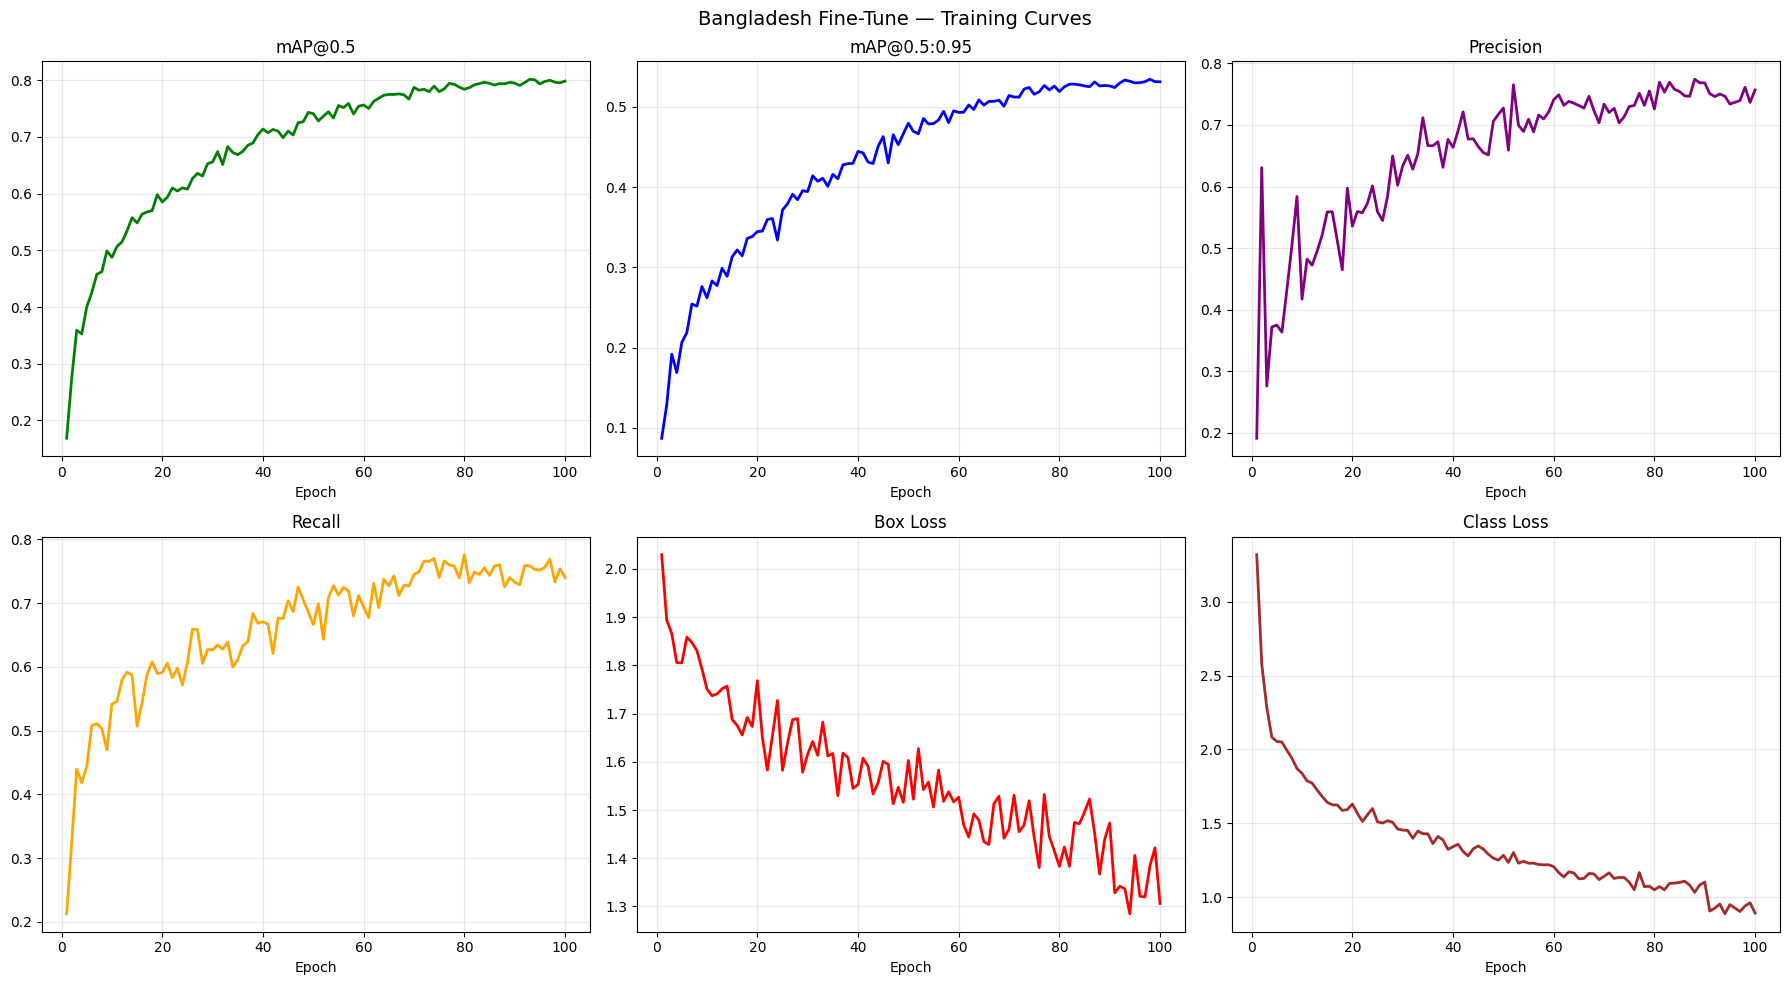


🏆 Best mAP@0.5 : 0.8014 at epoch 93


In [8]:
results_csv = MODELS_DIR / 'bangladesh_finetune' / 'results.csv'

if results_csv.exists():
    res_df = pd.read_csv(results_csv)
    res_df.columns = res_df.columns.str.strip()

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Bangladesh Fine-Tune — Training Curves', fontsize=14)

    metrics = [
        ('metrics/mAP50(B)',    'mAP@0.5',      'green',  axes[0,0]),
        ('metrics/mAP50-95(B)', 'mAP@0.5:0.95', 'blue',   axes[0,1]),
        ('metrics/precision(B)','Precision',    'purple', axes[0,2]),
        ('metrics/recall(B)',   'Recall',       'orange', axes[1,0]),
        ('train/box_loss',      'Box Loss',     'red',    axes[1,1]),
        ('train/cls_loss',      'Class Loss',   'brown',  axes[1,2]),
    ]

    for col, label, color, ax in metrics:
        if col in res_df.columns:
            ax.plot(res_df['epoch'], res_df[col], color=color, linewidth=2)
            ax.set_title(label)
            ax.set_xlabel('Epoch')
            ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(WORK_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
    plt.show()

    best_epoch = res_df['metrics/mAP50(B)'].idxmax()
    best_map   = res_df.loc[best_epoch, 'metrics/mAP50(B)']
    print(f'\n🏆 Best mAP@0.5 : {best_map:.4f} at epoch {int(res_df.loc[best_epoch, "epoch"])}')
else:
    print('results.csv not found — training may still be running or path is different.')

## 🔍 Cell 9 — Validation on Val Set (Best Weights)

In [9]:
print('Running validation with best weights...')
val_model = YOLO(str(FINETUNE_BEST))

val_metrics = val_model.val(
    data=str(YAML_PATH),
    imgsz=IMG_SIZE,
    batch=8,
    conf=0.001,
    iou=IOU_THRESH,
    augment=True,               # TTA during validation too
    verbose=True,
    plots=True,
    save_json=True,
)

print('\n' + '='*50)
print(f'  mAP@0.5      : {val_metrics.box.map50:.4f}')
print(f'  mAP@0.5:0.95 : {val_metrics.box.map:.4f}')
print(f'  Precision    : {val_metrics.box.mp:.4f}')
print(f'  Recall       : {val_metrics.box.mr:.4f}')
print('='*50)

# Per-class AP
print('\nPer-class AP@0.5:')
if hasattr(val_metrics.box, 'ap50'):
    for i, (name, ap) in enumerate(zip(CLASS_NAMES, val_metrics.box.ap50)):
        bar = '█' * int(ap * 30)
        print(f'  {i:2d} {name:<15} {ap:.3f}  {bar}')

Running validation with best weights...
Ultralytics 8.4.75 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 11,130,615 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3661.5±1036.0 MB/s, size: 344.3 KB)
val: Scanning /kaggle/working/dataset/val/labels.cache... 122 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 122/122 46.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.7it/s 9.2s
                   all        122       1532       0.77      0.772      0.807      0.535
              Rickshaw         51        232      0.725      0.754      0.829      0.408
            Motorcycle         56        155      0.785      0.626      0.731      0.344
                 Tempu         75        283      0.774      0.827      0.875      0.514
             Sedan Car         94        363      0.802       0.86      0.881      0.585


## 🔬 Cell 10 — SAHI Inference on Test Set

In [10]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

print('Loading model for SAHI inference...')
sahi_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics',
    model_path=str(FINETUNE_BEST),
    confidence_threshold=CONF_THRESH,
    device='cuda' if torch.cuda.is_available() else 'cpu',
)

test_images = sorted(list(TEST_IMAGES_DIR.glob('*.jpg')) +
                     list(TEST_IMAGES_DIR.glob('*.jpeg')) +
                     list(TEST_IMAGES_DIR.glob('*.png')))
print(f'Test images found: {len(test_images)}')

all_predictions = {}   # image_id → list of (class_id, conf, cx, cy, w, h)

for i, img_path in enumerate(test_images):
    if i % 50 == 0:
        print(f'  [{i}/{len(test_images)}] Processing {img_path.name}...')

    img = Image.open(img_path)
    W, H = img.size

    try:
        result = get_sliced_prediction(
            str(img_path),
            sahi_model,
            slice_height=SAHI_SLICE_H,
            slice_width=SAHI_SLICE_W,
            overlap_height_ratio=SAHI_OVERLAP,
            overlap_width_ratio=SAHI_OVERLAP,
            perform_standard_pred=True,     # Also run full-image prediction
            postprocess_type='NMS',
            postprocess_match_threshold=0.5,
            verbose=0,
        )

        preds = []
        for obj in result.object_prediction_list:
            cls_id = int(obj.category.id)
            conf   = float(obj.score.value)
            bbox   = obj.bbox  # xyxy absolute

            x1, y1, x2, y2 = bbox.minx, bbox.miny, bbox.maxx, bbox.maxy
            # Convert to normalized cx, cy, w, h
            cx = ((x1 + x2) / 2) / W
            cy = ((y1 + y2) / 2) / H
            bw = (x2 - x1) / W
            bh = (y2 - y1) / H

            # Clamp to [0, 1]
            cx = max(0, min(1, cx))
            cy = max(0, min(1, cy))
            bw = max(0, min(1, bw))
            bh = max(0, min(1, bh))

            if bw > 0 and bh > 0:
                preds.append((cls_id, conf, cx, cy, bw, bh))

        all_predictions[img_path.stem] = preds

    except Exception as e:
        print(f'  ⚠️  Error on {img_path.name}: {e}')
        all_predictions[img_path.stem] = []

total_dets = sum(len(v) for v in all_predictions.values())
print(f'\n✅ SAHI inference complete.')
print(f'   Total detections : {total_dets}')
print(f'   Avg per image    : {total_dets / len(test_images):.1f}')

Loading model for SAHI inference...
Test images found: 327
  [0/327] Processing CCTV01^20260318-110000-20260318-120000_000061.jpg...
  [50/327] Processing CCTV01^20260318-110000-20260318-120000_000295.jpg...
  [100/327] Processing CCTV01^20260318-110000-20260318-120000_000670.jpg...
  [150/327] Processing CCTV02^20260511-140000-20260511-142440_002469.jpg...
  [200/327] Processing CCTV07^20260116-060000-20260116-065959_003704.jpg...
  [250/327] Processing CCTV10^20251112-170000-20251112-175959_004528.jpg...
  [300/327] Processing CCTV10^20251112-220000-20251112-225959_006504.jpg...

✅ SAHI inference complete.
   Total detections : 18945
   Avg per image    : 57.9


## 📄 Cell 11 — Generate Submission CSV

In [11]:
def build_prediction_string(preds):
    """Build space-separated prediction string for submission."""
    if not preds:
        return ''
    parts = []
    # Sort by confidence descending
    for cls_id, conf, cx, cy, bw, bh in sorted(preds, key=lambda x: -x[1]):
        parts.append(f'{cls_id} {conf:.4f} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}')
    return ' '.join(parts)

rows = []
for img_path in sorted(test_images):
    img_id = img_path.stem
    preds  = all_predictions.get(img_id, [])
    rows.append({
        'image_id': img_id,
        'PredictionString': build_prediction_string(preds)
    })

submission_df = pd.DataFrame(rows)

# Sanity checks
print(f'Submission rows       : {len(submission_df)}')
print(f'Empty predictions     : {(submission_df["PredictionString"] == "").sum()}')
print(f'Non-empty predictions : {(submission_df["PredictionString"] != "").sum()}')
print('\nSample rows:')
print(submission_df.head(3).to_string(index=False))

SUBMISSION_PATH = SUBMISSION_DIR / 'submission_sahi.csv'
submission_df.to_csv(SUBMISSION_PATH, index=False)
print(f'\n✅ Submission saved → {SUBMISSION_PATH}')

Submission rows       : 327
Empty predictions     : 0
Non-empty predictions : 327

Sample rows:
                                     image_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

## ✅ Cell 12 — Validate Submission Format

In [12]:
def validate_submission(submission_path):
    df_sub = pd.read_csv(submission_path)
    errors = []

    # Check columns
    if list(df_sub.columns) != ['image_id', 'PredictionString']:
        errors.append(f'Wrong columns: {list(df_sub.columns)}')

    for _, row in df_sub.iterrows():
        ps = str(row['PredictionString']).strip()
        if ps == '' or ps == 'nan':
            continue
        tokens = ps.split()
        if len(tokens) % 6 != 0:
            errors.append(f"{row['image_id']}: token count {len(tokens)} not divisible by 6")
            continue
        for i in range(0, len(tokens), 6):
            cls_id = int(tokens[i])
            conf   = float(tokens[i+1])
            vals   = [float(x) for x in tokens[i+2:i+6]]
            if not (0 <= cls_id <= 12):
                errors.append(f"{row['image_id']}: invalid class_id {cls_id}")
            if not (0.0 <= conf <= 1.0):
                errors.append(f"{row['image_id']}: conf {conf} out of [0,1]")
            if any(v < 0 or v > 1 for v in vals):
                errors.append(f"{row['image_id']}: bbox values out of [0,1]: {vals}")

    if errors:
        print(f'❌ {len(errors)} errors found:')
        for e in errors[:10]:
            print(f'   {e}')
    else:
        print(f'✅ Submission valid! {len(df_sub)} rows, all format checks passed.')

    # Stats
    non_empty = df_sub[df_sub['PredictionString'].str.strip().fillna('') != '']
    print(f'   Images with detections: {len(non_empty)} / {len(df_sub)}')

validate_submission(SUBMISSION_PATH)

✅ Submission valid! 327 rows, all format checks passed.
   Images with detections: 327 / 327


## 💾 Cell 13 — Save All Models & Artifacts

In [13]:
import zipfile

SAVE_PATH = WORK_DIR / 'roadvision_models.zip'

files_to_save = [
    (FINETUNE_BEST,  'models/finetune_best.pt'),
    (FINETUNE_LAST,  'models/finetune_last.pt'),
    (VISDRONE_BEST,  'models/visdrone_best.pt'),
    (YAML_PATH,      'configs/bangladesh.yaml'),
    (SUBMISSION_PATH,'submission/submission_sahi.csv'),
    (WORK_DIR / 'training_curves.png', 'plots/training_curves.png'),
    (WORK_DIR / 'eda_distribution.png','plots/eda_distribution.png'),
]

with zipfile.ZipFile(SAVE_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    for src, arcname in files_to_save:
        src = Path(src)
        if src.exists():
            zf.write(src, arcname)
            print(f'  ✅ {arcname}')
        else:
            print(f'  ⚠️  Missing: {src}')

size_mb = SAVE_PATH.stat().st_size / 1e6
print(f'\n📦 Saved → {SAVE_PATH}  ({size_mb:.1f} MB)')
print('\nAll done! 🎉 Submit submission/submission_sahi.csv to the leaderboard.')

  ✅ models/finetune_best.pt
  ✅ models/finetune_last.pt
  ⚠️  Missing: yolov11l.pt
  ✅ configs/bangladesh.yaml
  ✅ submission/submission_sahi.csv
  ✅ plots/training_curves.png
  ✅ plots/eda_distribution.png

📦 Saved → /kaggle/working/roadvision_models.zip  (42.1 MB)

All done! 🎉 Submit submission/submission_sahi.csv to the leaderboard.


## 🔁 Cell 14 — [OPTIONAL] TTA-Only Inference (Fallback if SAHI is slow)

In [14]:
# Run this cell ONLY if SAHI is too slow or crashes
# This uses Ultralytics built-in TTA — faster but slightly lower mAP

print('Running TTA-only inference (fallback)...')
tta_model = YOLO(str(FINETUNE_BEST))

tta_results = tta_model.predict(
    source=str(TEST_IMAGES_DIR),
    imgsz=IMG_SIZE,
    augment=True,           # TTA: multi-scale + flip
    conf=CONF_THRESH,
    iou=IOU_THRESH,
    save=False,
    verbose=False,
    stream=True,            # Memory-efficient streaming
)

tta_predictions = {}
for r in tta_results:
    img_id = Path(r.path).stem
    W, H   = r.orig_shape[1], r.orig_shape[0]
    preds  = []

    if r.boxes is not None and len(r.boxes) > 0:
        boxes  = r.boxes.xywhn.cpu().numpy()   # Already normalized cx,cy,w,h
        confs  = r.boxes.conf.cpu().numpy()
        clss   = r.boxes.cls.cpu().numpy().astype(int)

        for cls_id, conf, (cx, cy, bw, bh) in zip(clss, confs, boxes):
            preds.append((int(cls_id), float(conf),
                          float(cx), float(cy), float(bw), float(bh)))

    tta_predictions[img_id] = preds

# Build TTA submission
tta_rows = []
for img_path in sorted(test_images):
    img_id = img_path.stem
    preds  = tta_predictions.get(img_id, [])
    tta_rows.append({
        'image_id': img_id,
        'PredictionString': build_prediction_string(preds)
    })

TTA_SUBMISSION_PATH = SUBMISSION_DIR / 'submission_tta.csv'
pd.DataFrame(tta_rows).to_csv(TTA_SUBMISSION_PATH, index=False)

print(f'✅ TTA submission saved → {TTA_SUBMISSION_PATH}')
validate_submission(TTA_SUBMISSION_PATH)

Running TTA-only inference (fallback)...
✅ TTA submission saved → /kaggle/working/submission/submission_tta.csv
✅ Submission valid! 327 rows, all format checks passed.
   Images with detections: 327 / 327


---
## 📋 Summary

| Step | Detail |
|---|---|
| Base model | YOLOv11x (COCO pretrained) |
| Phase 1 | VisDrone intermediate pretraining — 50 epochs, imgsz=1280 |
| Phase 2 | Bangladesh fine-tuning — 250 epochs, imgsz=1280, AdamW, cosine LR |
| Augmentation | Mosaic, CopyPaste, MixUp, HSV, Scale, Erasing, multi-scale |
| Inference | SAHI sliced prediction (640×640 tiles, 20% overlap) + full image |
| Fallback | Ultralytics TTA (Cell 14) |
| Output | `submission/submission_sahi.csv` |

**Submit:** `/kaggle/working/submission/submission_sahi.csv`